<a href="https://colab.research.google.com/github/TIMMY-AKLIS-SURESH/ECG_Project/blob/main/Copy_of_ECG_ConvNeXt_Atto_CBAM_TRAIN_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 12-Lead ECG Classification — ConvNeXt-Atto + CBAM  |  **TRAINING (v2, leakage-free evaluation)**
Runs preprocessing + training and **saves everything to Google Drive** for the *test notebook* (`..._TEST_v2`).

## What changed compared with the first training notebook, and why

| # | Problem in the old notebook | Fix in v2 |
|---|---|---|
| 1 | **Random image-level split.** If the dataset holds several images per patient (the folder names `240x12=2880` suggest 12 per patient), the same patient lands in both train and test → inflated test accuracy | **Patient-level (group) split.** Section 5 detects the layout from the folder names, derives a patient id from the file names, **verifies** the number of patients per class, and refuses to continue if it cannot (override with `GROUP_REGEX`). A hard assertion proves no patient is in two splits |
| 2 | **The test set chose the best epoch** (25 test evaluations) → reported accuracy was optimistic | **Train / validation / test.** Checkpoint selection and early stopping use *validation* only. The test set is evaluated **once**, at the end |
| 3 | Images whose ROI step failed were **silently dropped** from train *and* test | Same robust preprocessing as the test notebook (cascade of ROI + grid-removal strategies, quality check); nothing readable is dropped, and a log shows which strategy handled each image |
| 4 | **Horizontal flip** (training and TTA) mirrors time and swaps the lead columns | Removed |
| 5 | Rotations filled corners with **black** on a white page | White fill |
| 6 | Every image **squashed** to 448×448 regardless of shape | **Letterbox**: resize keeping the aspect ratio, pad with white. Input is 320×576 (the shape of your crops) |
| 7 | Backbone LR 3e-5 was very low; only the **last batch's loss** was printed; no train accuracy | LR 1e-4 / 1e-3 with warm-up + cosine, gradient clipping, per-epoch train loss/acc + val loss/acc/macro-F1, curves saved, early stopping |
| 8 | Little robustness to scanner differences | Extra augmentation: small affine (white fill), random low-resolution, blur |
| 9 | No way to use the other dataset for training | Optional `EXTRA_DATA_SOURCE`: a second labeled dataset is added to training and its **own held-out part** is reported separately |

Everything the test notebook needs (class names, input geometry, QC thresholds, held-out test images) is written to `SAVE_DIR`.
The default `SAVE_DIR` ends in `_v2`, so your **old model is not overwritten**.

**Before you run:** `Runtime → Change runtime type → GPU`, then run the cells top to bottom.

## 0. Setup

In [ ]:
import subprocess, sys
subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "timm"])
try:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pymupdf"])   # optional: PDF inputs
except Exception as e:
    print("pymupdf not installed (PDF files, if any, will be reported as unreadable):", e)

import torch
print("PyTorch :", torch.__version__)
print("GPU     :", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE")
if not torch.cuda.is_available():
    print("WARNING: no GPU detected -> training will be very slow. Use Runtime > Change runtime type > GPU.")

PyTorch : 2.11.0+cu130
GPU     : Tesla T4


## 1. Mount Google Drive

In [ ]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


## 2. Settings
Everything you may want to change is in this one cell.

In [ ]:
import os, json, re, io, math, time, shutil, zipfile, random

# ----------------------------- where things are saved -----------------------------
SAVE_DIR = "/content/drive/MyDrive/ECG_ConvNeXt_Atto_CBAM_v2"      # NEW folder: the old model is not overwritten
WORK_DIR = "/content"                                               # local scratch space (preprocessed images)

# ----------------------------- data -----------------------------------------------
# "upload"                         -> you will be asked to upload the dataset .zip
# "/content/drive/MyDrive/x.zip"   -> zip in Drive,   "/content/drive/MyDrive/x" -> folder in Drive
DATA_SOURCE = "upload"
# OPTIONAL second labeled dataset (class sub-folders). It is added to training; its own held-out part is reported
# separately. Use this to adapt the model to the external dataset. None = off.
EXTRA_DATA_SOURCE = None
# If the class folders of the extra dataset are named differently from the main dataset:
#   {"folder name": "exact main class name"}  or  {"folder name": class index}
FOLDER_TO_CLASS = {}

# ----------------------------- patient-level grouping -------------------------------
# Regex (applied to the file name WITHOUT extension) whose group(1) is the patient id.
# Leave None to auto-detect (see section 5).  Example for "MI(12)_3.jpg": r"^(.*?\(\d+\))[_\- ]*\d{1,2}$"
GROUP_REGEX = None
REQUIRE_PATIENT_GROUPS = True      # True: stop if the patient id cannot be verified when there are several images per patient

# ----------------------------- split ------------------------------------------------
VAL_FRAC, TEST_FRAC = 0.15, 0.15   # fractions of PATIENTS per class (and per source)

# ----------------------------- input geometry -----------------------------------------
IMG_H, IMG_W = 320, 576            # multiples of 32; ~1.8:1 like your ECG crops
RESIZE_MODE  = "letterbox"         # keep aspect ratio, pad with white
ROT_FILL     = 255                 # white corners for rotations
TTA_HFLIP    = False               # never mirror an ECG

# ----------------------------- training ---------------------------------------------
PRETRAINED       = True            # ImageNet weights for the backbone
NUM_EPOCHS       = 40
PATIENCE         = 10              # early stopping on validation macro-F1
BATCH_SIZE       = 16
LR_BACKBONE      = 1e-4
LR_HEAD          = 1e-3
WARMUP_EPOCHS    = 2
WEIGHT_DECAY     = 1e-2
GRAD_CLIP        = 1.0
USE_CLASS_WEIGHTS = True
FOCAL_GAMMA      = 2.0
LABEL_SMOOTHING  = 0.03
NUM_WORKERS      = 2
SEED             = 42

# ----------------------------- preprocessing ---------------------------------------
MIN_ROI_AREA_FRAC = 0.20           # a detected ROI smaller than this fraction of the image counts as failed

# ----------------------------- derived paths (no need to edit) ---------------------
os.makedirs(SAVE_DIR, exist_ok=True)
CKPT_PATH    = os.path.join(SAVE_DIR, "best_convnext_atto_peak.pth")
CONFIG_PATH  = os.path.join(SAVE_DIR, "config.json")
HISTORY_PATH = os.path.join(SAVE_DIR, "training_history.json")
SPLIT_CSV    = os.path.join(SAVE_DIR, "split_manifest.csv")
HELDOUT_DIR  = os.path.join(SAVE_DIR, "heldout_test_images")
CLEAN_DIR    = os.path.join(WORK_DIR, "ECG_Cleaned")
CANVAS_DIR   = os.path.join(WORK_DIR, "ECG_Canvas")
print("Artifacts will be saved in:", SAVE_DIR)

Artifacts will be saved in: /content/drive/MyDrive/ECG_ConvNeXt_Atto_CBAM_v2


## 3. Imports, seeds, device and transforms

In [ ]:
import zipfile
import cv2
import numpy as np
from PIL import Image, ImageOps, ImageFile
import matplotlib.pyplot as plt
from tqdm import tqdm
import textwrap
import seaborn as sns
import pandas as pd
from collections import Counter
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.amp as amp
import timm
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import (classification_report, confusion_matrix,
                             precision_recall_fscore_support, f1_score)

Image.MAX_IMAGE_PIXELS = None
ImageFile.LOAD_TRUNCATED_IMAGES = True

random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = (device.type == "cuda")
print(f"Using device: {device}")

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

# ---- transforms shared with the test notebook (identical code) ----

# Needs these globals: IMG_H, IMG_W, RESIZE_MODE, ROT_FILL, TTA_HFLIP, IMAGENET_MEAN, IMAGENET_STD
class Letterbox:
    """Resize keeping the aspect ratio so the image fits inside (h, w), then pad with white to exactly (h, w)."""
    def __init__(self, h, w, fill=255):
        self.h, self.w, self.fill = h, w, fill

    def __call__(self, img):
        W0, H0 = img.size
        s = min(self.w / W0, self.h / H0)
        nw, nh = max(1, int(round(W0 * s))), max(1, int(round(H0 * s)))
        if (nw, nh) != (W0, H0):
            img = img.resize((nw, nh), Image.BICUBIC)
        canvas = Image.new("RGB", (self.w, self.h), (self.fill,) * 3)
        canvas.paste(img, ((self.w - nw) // 2, (self.h - nh) // 2))
        return canvas


def base_resize():
    if RESIZE_MODE == "letterbox":
        return Letterbox(IMG_H, IMG_W)
    return transforms.Resize((IMG_H, IMG_W))      # legacy: squash to a fixed size (old training notebook)


def make_view(*extra):
    """base resize -> (extra aug) -> ToTensor -> Normalize"""
    return transforms.Compose([
        base_resize(),
        *extra,
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])


eval_transforms = make_view()

# test-time-augmentation pool
tta_transform_pool = [eval_transforms]                                              # original
if TTA_HFLIP:                                                                       # legacy only
    tta_transform_pool.append(make_view(transforms.RandomHorizontalFlip(p=1.0)))
tta_transform_pool += [
    make_view(transforms.RandomRotation(degrees=(3, 3),   fill=ROT_FILL)),          # +3 deg
    make_view(transforms.RandomRotation(degrees=(-3, -3), fill=ROT_FILL)),          # -3 deg
    make_view(transforms.RandomRotation(degrees=(5, 5),   fill=ROT_FILL)),          # +5 deg
    make_view(transforms.RandomRotation(degrees=(-5, -5), fill=ROT_FILL)),          # -5 deg
    make_view(transforms.ColorJitter(brightness=0.05, contrast=0.05)),              # jitter
]
print(f"Input {IMG_H}x{IMG_W} | resize={RESIZE_MODE} | rotation fill={ROT_FILL} | "
      f"hflip in TTA={TTA_HFLIP} | TTA views={len(tta_transform_pool)}")

Using device: cuda
Input 320x576 | resize=letterbox | rotation fill=255 | hflip in TTA=False | TTA views=6


## 4. Robust preprocessing functions (ROI crop + grid removal)
Identical to the test notebook. The first strategy of each cascade is the original training algorithm,
so images that look like your dataset are processed exactly as before; the other strategies only run when it fails.

In [ ]:
IMG_EXTS = (".jpg", ".jpeg", ".jpe", ".jfif", ".png", ".bmp", ".tif", ".tiff", ".webp", ".pdf")

# ---------------------------------------------------------------------------------
# 1. Robust image loading -> uint8 BGR array (or None if truly unreadable)
# ---------------------------------------------------------------------------------
def _pil_to_bgr(pil):
    pil = ImageOps.exif_transpose(pil)
    if pil.mode in ("I;16", "I", "F"):                       # 16-bit / float images
        arr = np.array(pil).astype(np.float32)
        arr = (arr - arr.min()) / max(1e-6, float(arr.max() - arr.min())) * 255.0
        pil = Image.fromarray(arr.astype(np.uint8)).convert("RGB")
    elif pil.mode in ("RGBA", "LA", "PA") or (pil.mode == "P" and "transparency" in pil.info):
        pil = pil.convert("RGBA")                            # transparent pixels -> white (not black)
        bg = Image.new("RGBA", pil.size, (255, 255, 255, 255))
        bg.alpha_composite(pil)
        pil = bg.convert("RGB")
    else:
        pil = pil.convert("RGB")
    return np.array(pil)[..., ::-1].copy()


def load_bgr(path):
    ext = os.path.splitext(path)[1].lower()
    if ext == ".pdf":
        try:
            import fitz                                      # PyMuPDF
            doc = fitz.open(path)
            pix = doc[0].get_pixmap(dpi=200, alpha=False)
            arr = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.width, pix.n)
            if pix.n == 1:
                return cv2.cvtColor(arr, cv2.COLOR_GRAY2BGR)
            return cv2.cvtColor(arr[..., :3], cv2.COLOR_RGB2BGR)
        except Exception:
            return None
    try:
        with Image.open(path) as pil:
            pil.load()
            return _pil_to_bgr(pil)
    except Exception:
        pass
    try:                                                     # OpenCV as a second opinion
        data = np.fromfile(path, dtype=np.uint8)
        img = cv2.imdecode(data, cv2.IMREAD_COLOR)
        if img is not None:
            return img
    except Exception:
        pass
    return None


# ---------------------------------------------------------------------------------
# 2. ROI detection - cascade of strategies, never fails
# ---------------------------------------------------------------------------------
def _odd(n, lo=3):
    n = max(lo, int(n))
    return n if n % 2 == 1 else n + 1


def _roi_grid_box(gray, kernel_len=25, block=31, C=10, min_area_frac=0.05):
    """The TRAINING algorithm (steps 3-14) with tunable parameters. Returns (x1, y1, x2, y2).
    With the defaults (25, 31, 10) it is identical to the training notebook, except that y1 is
    clamped to >= 0 (in training, a negative y1 produced an empty crop and the image 'failed')."""
    H, W = gray.shape
    blurred = cv2.GaussianBlur(gray, (5, 5), 0)
    binary = cv2.adaptiveThreshold(blurred, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
                                   cv2.THRESH_BINARY_INV, block, C)
    hk = cv2.getStructuringElement(cv2.MORPH_RECT, (kernel_len, 1))
    vk = cv2.getStructuringElement(cv2.MORPH_RECT, (1, kernel_len))
    structure = cv2.bitwise_or(cv2.morphologyEx(binary, cv2.MORPH_OPEN, hk),
                               cv2.morphologyEx(binary, cv2.MORPH_OPEN, vk))
    contours, _ = cv2.findContours(structure, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        raise ValueError("no grid structure")
    best = None
    for c in contours:
        x, y, w, h = cv2.boundingRect(c)
        a = w * h
        if a > min_area_frac * H * W and (best is None or a > best[4]):
            best = (x, y, w, h, a)
    if best is None:
        raise ValueError("no large grid region")
    x, y, w, h, _ = best
    x1, y1, x2, y2 = x, y, x + w, y + h

    # refine ONLY the top boundary (first strong ECG/grid activity)
    roi_gray = gray[y1:y2, x1:x2]
    roi_binary = cv2.threshold(roi_gray, 180, 255, cv2.THRESH_BINARY_INV)[1]
    row_pixels = np.sum(roi_binary > 0, axis=1)
    smooth_window = max(5, int(0.005 * h))
    kernel = np.ones(smooth_window) / smooth_window
    row_signal = np.convolve(row_pixels, kernel, mode="same")
    threshold = np.max(row_signal) * 0.18
    active_rows = np.where(row_signal > threshold)[0]
    if len(active_rows) > 0:
        detected_top = active_rows[0]
        safety = max(2, int(0.005 * h))
        new_y1 = y1 + detected_top - safety
        max_allowed_shift = int(0.08 * h)
        if new_y1 - y1 <= max_allowed_shift:
            y1 = max(0, new_y1)                              # <-- clamp (the training code could go negative)

    margin_x = int(0.01 * W)
    x1 = max(0, x1 - margin_x)
    x2 = min(W, x2 + margin_x)
    return x1, y1, x2, y2


def _roi_content_box(det):
    """No-grid fallback: bounding box of everything that is not plain paper."""
    gray = cv2.cvtColor(det, cv2.COLOR_BGR2GRAY)
    hsv = cv2.cvtColor(det, cv2.COLOR_BGR2HSV)
    h, w = gray.shape
    paper = float(np.percentile(gray, 95))
    content = ((gray < paper - 25) | ((hsv[..., 1] > 25) & (hsv[..., 2] > 80))).astype(np.uint8) * 255
    content = cv2.morphologyEx(content, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))
    k = _odd(0.01 * max(h, w), 5)
    content = cv2.morphologyEx(content, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_RECT, (k, k)))
    contours, _ = cv2.findContours(content, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if len(contours) == 0:
        raise ValueError("no content")
    x, y, bw, bh = max((cv2.boundingRect(c) for c in contours), key=lambda r: r[2] * r[3])
    mx, my = int(0.005 * w), int(0.005 * h)
    return max(0, x - mx), max(0, y - my), min(w, x + bw + mx), min(h, y + bh + my)


def _roi_sane(box, h, w):
    x1, y1, x2, y2 = box
    bw, bh = x2 - x1, y2 - y1
    if bw <= 0 or bh <= 0:
        return False
    return (bw * bh) / float(h * w) >= MIN_ROI_AREA_FRAC and bw >= 0.4 * w and bh >= 0.25 * h


def detect_roi(bgr):
    """Returns ((x1, y1, x2, y2), method_name). Never raises; the worst case is the full image."""
    H, W = bgr.shape[:2]
    f, det = 1.0, bgr
    if max(H, W) > 4000:                                     # speed/memory guard for huge scans
        f = 4000.0 / max(H, W)
        det = cv2.resize(bgr, (max(1, int(W * f)), max(1, int(H * f))), interpolation=cv2.INTER_AREA)
    gray = cv2.cvtColor(det, cv2.COLOR_BGR2GRAY)
    h, w = gray.shape
    Ld = max(h, w)

    def to_full(box):
        x1, y1, x2, y2 = [int(round(v / f)) for v in box]
        return max(0, x1), max(0, y1), min(W, x2), min(H, y2)

    attempts = [
        ("train_exact",      dict(kernel_len=25, block=31, C=10)),                                   # == training
        ("grid_sensitive",   dict(kernel_len=25, block=31, C=4)),                                    # fainter grids
        ("grid_scaled",      dict(kernel_len=max(15, int(0.015 * Ld)), block=_odd(0.02 * Ld, 31), C=8)),
        ("grid_scaled_long", dict(kernel_len=max(25, int(0.03 * Ld)),  block=_odd(0.03 * Ld, 31), C=4)),
        ("grid_small",       dict(kernel_len=11, block=21, C=4)),                                    # low-res images
    ]
    seen = set()
    for name, p in attempts:
        key = tuple(sorted(p.items()))
        if key in seen:
            continue
        seen.add(key)
        try:
            box = _roi_grid_box(gray, **p)
        except Exception:
            continue
        if _roi_sane(box, h, w):
            return to_full(box), name
    try:
        box = _roi_content_box(det)
        if _roi_sane(box, h, w):
            return to_full(box), "content_bbox"
    except Exception:
        pass
    return (0, 0, W, H), "full_image"


# ---------------------------------------------------------------------------------
# 3. Grid removal - cascade with a quality check
# ---------------------------------------------------------------------------------
def _lab_chroma(bgr):
    lab = cv2.cvtColor(bgr, cv2.COLOR_BGR2Lab)
    L, a, b = cv2.split(lab)
    chroma = np.sqrt((a.astype(np.float32) - 128.0) ** 2 + (b.astype(np.float32) - 128.0) ** 2)
    return L, a, b, chroma


def clean_train_exact(bgr_img):
    """The TRAINING grid removal (Lab + HSV), unchanged."""
    lab = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2Lab)
    l_channel, a_channel, b_channel = cv2.split(lab)
    grid_mask = (a_channel > 126) & (l_channel > 140) & (l_channel < 250)
    kernel = np.ones((3, 3), np.uint8)
    grid_mask = cv2.dilate(grid_mask.astype(np.uint8), kernel, iterations=1) > 0
    cleaned_img = bgr_img.copy()
    cleaned_img[grid_mask] = [255, 255, 255]
    hsv = cv2.cvtColor(cleaned_img, cv2.COLOR_BGR2HSV)
    pink_mask = cv2.inRange(hsv, np.array([140, 5, 200]), np.array([180, 40, 255]))
    cleaned_img[pink_mask > 0] = [255, 255, 255]
    return cleaned_img


def clean_chroma(bgr_img, chroma_thr=7.0, l_min=130):
    """Colour-based: whiten any light coloured pixel (any grid hue). Neutral grey/black ink is untouched."""
    L, a, b, chroma = _lab_chroma(bgr_img)
    mask = (chroma > chroma_thr) & (L > l_min)
    mask = cv2.dilate(mask.astype(np.uint8), np.ones((3, 3), np.uint8)) > 0
    out = bgr_img.copy()
    out[mask] = 255
    return out


def clean_ink_only(bgr_img):
    """Last resort: keep only dark ink (Otsu), everything else white."""
    gray = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)
    otsu, _ = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    ink = gray < min(float(otsu), 160.0)
    out = np.full_like(bgr_img, 255)
    out[ink] = bgr_img[ink]
    return out


# thresholds are re-calibrated from your own held-out images in the next cell
QC = dict(ink_lo=0.0005, ink_hi=0.35, resid_hi=0.02, ink_ref=0.02)

def clean_metrics(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    L, a, b, chroma = _lab_chroma(bgr)
    return dict(ink=float((gray < 170).mean()),                      # dark pixels = ECG trace + text
                resid=float(((chroma > 7) & (L > 130)).mean()))      # leftover light coloured (grid-like) pixels


def clean_grid(roi_bgr):
    """Try the removal methods in order; accept the first whose result passes the quality check.
    Returns (cleaned_bgr, method_name, metrics, qc_passed)."""
    best = None
    for name, fn in (("train_exact", clean_train_exact), ("chroma", clean_chroma), ("ink_only", clean_ink_only)):
        try:
            out = fn(roi_bgr)
        except Exception:
            continue
        m = clean_metrics(out)
        ok = (QC["ink_lo"] <= m["ink"] <= QC["ink_hi"]) and (m["resid"] <= QC["resid_hi"])
        if ok:
            return out, name, m, True
        score = abs(np.log((m["ink"] + 1e-4) / (QC["ink_ref"] + 1e-4))) + 20.0 * m["resid"]
        if best is None or score < best[3]:
            best = (out, name, m, score)
    if best is None:
        return roi_bgr, "none", clean_metrics(roi_bgr), False
    return best[0], best[1], best[2], False


# ---------------------------------------------------------------------------------
# 4. One image -> (RGB array, log record). Only an unreadable file returns (None, ...).
# ---------------------------------------------------------------------------------
def preprocess_image(path, return_stages=False):
    bgr = load_bgr(path)
    if bgr is None:
        return None, {"status": "UNREADABLE"}
    H, W = bgr.shape[:2]
    try:
        (x1, y1, x2, y2), roi_method = detect_roi(bgr)
        roi = bgr[y1:y2, x1:x2]
        cleaned, clean_method, m, qc = clean_grid(roi)
        rec = dict(status="OK", orig_w=W, orig_h=H, roi_w=x2 - x1, roi_h=y2 - y1,
                   roi_frac=round((x2 - x1) * (y2 - y1) / float(H * W), 3),
                   roi_method=roi_method, clean_method=clean_method, qc_pass=bool(qc),
                   ink_frac=round(m["ink"], 5), resid_frac=round(m["resid"], 5))
    except Exception as e:                                   # absolute safety net: keep the image anyway
        roi, cleaned = bgr, bgr
        rec = dict(status="EXCEPTION_FALLBACK:" + type(e).__name__, orig_w=W, orig_h=H, roi_w=W, roi_h=H,
                   roi_frac=1.0, roi_method="exception_full", clean_method="none", qc_pass=False,
                   ink_frac=np.nan, resid_frac=np.nan)
    rgb = cv2.cvtColor(cleaned, cv2.COLOR_BGR2RGB)
    if return_stages:
        rec["_raw"] = cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)
        rec["_roi"] = cv2.cvtColor(roi, cv2.COLOR_BGR2RGB)
    return rgb, rec

print("Robust preprocessing ready.")

Robust preprocessing ready.


## 5. Collect the images and derive patient ids

In [ ]:
def prepare_source(src, dest, label):
    """Return a folder containing the images of `src` (upload / zip / folder)."""
    if src == "upload":
        from google.colab import files as gfiles
        print(f"Upload the {label} dataset as a ZIP:")
        up = gfiles.upload()
        zp = "/content/" + list(up.keys())[0]
    elif os.path.isdir(src):
        return src
    elif src.lower().endswith(".zip") and os.path.exists(src):
        zp = src
    else:
        raise FileNotFoundError(f"{label}: source not found: {src}")
    if os.path.exists(dest):
        shutil.rmtree(dest)
    os.makedirs(dest)
    with zipfile.ZipFile(zp, "r") as zf:
        for m in zf.infolist():
            base = os.path.basename(m.filename)
            if m.filename.startswith("__MACOSX") or base.startswith("._") or base == ".DS_Store":
                continue
            zf.extract(m, dest)
    return dest


def collect_images(root):
    found = []
    for r, dirs, fs in os.walk(root):
        dirs[:] = [d for d in dirs if d != "__MACOSX" and not d.startswith(".")]
        for f in fs:
            if not f.startswith(".") and f.lower().endswith(IMG_EXTS):
                found.append(os.path.join(r, f))
    return sorted(found)


MAIN_ROOT = prepare_source(DATA_SOURCE, os.path.join(WORK_DIR, "ECG_Dataset"), "main")
main_files = collect_images(MAIN_ROOT)
man = pd.DataFrame({"source": "main", "raw_path": main_files,
                    "class": [os.path.basename(os.path.dirname(p)) for p in main_files]})
class_names = sorted(man["class"].unique())
NUM_CLASSES = len(class_names)
assert NUM_CLASSES >= 2, f"Found only {NUM_CLASSES} class folder(s) - check the dataset layout: {MAIN_ROOT}"
print(f"Main dataset: {len(man)} images in {NUM_CLASSES} classes")
for i, c in enumerate(class_names):
    print(f"  {i}: {c}  ->  {int((man['class'] == c).sum())} images")

# ---------------- optional extra dataset ----------------
def _norm(s):
    return re.sub(r"[^a-z0-9]", "", str(s).lower())

def _words(s):
    return set(re.findall(r"[a-z0-9]+", str(s).lower()))
_norm_classes = {_norm(c): c for c in class_names}
_manual = {}
for k, v in FOLDER_TO_CLASS.items():
    cls = class_names[v] if isinstance(v, int) else v
    if cls not in class_names:
        raise ValueError(f"FOLDER_TO_CLASS target {v!r} is not a main class. Valid classes: {class_names}")
    _manual[_norm(k)] = cls

def resolve_folder(name):
    n = _norm(name)
    if n in _manual:
        return _manual[n]
    if n in _norm_classes:
        return _norm_classes[n]
    if len(n) >= 6:
        hits = [c for nc, c in _norm_classes.items() if n in nc or nc in n]
        if len(hits) > 1:                                    # e.g. "Normal" is inside "abnormal": keep whole-word matches only
            w = _words(name)
            hits = [c for c in hits if w and w <= _words(c)]
        if len(hits) == 1:
            return hits[0]
    return None

if EXTRA_DATA_SOURCE:
    extra_root = prepare_source(EXTRA_DATA_SOURCE, os.path.join(WORK_DIR, "ECG_Extra_Dataset"), "extra")
    extra_files = collect_images(extra_root)
    ex = pd.DataFrame({"source": "extra", "raw_path": extra_files,
                       "folder": [os.path.basename(os.path.dirname(p)) for p in extra_files]})
    ex["class"] = ex["folder"].map(resolve_folder)
    tab = ex.groupby("folder")["class"].agg(lambda s: s.iloc[0] if s.notna().any() else "-- NOT MATCHED --").to_frame("mapped_to")
    tab["n_images"] = ex.groupby("folder").size()
    print("\nExtra dataset folder -> class mapping:")
    display(tab)
    dropped = int(ex["class"].isna().sum())
    if dropped:
        print(f"WARNING: {dropped} extra images are in unmatched folders and are ignored. Map them with FOLDER_TO_CLASS.")
    man = pd.concat([man, ex.dropna(subset=["class"]).drop(columns="folder")], ignore_index=True)
    print(f"Extra dataset: {int((man['source'] == 'extra').sum())} images added.")
man = man.reset_index(drop=True)

Upload the main dataset as a ZIP:


Saving ECG_Dataset.zip to ECG_Dataset.zip
Main dataset: 928 images in 4 classes
  0: ECG Images of Myocardial Infarction Patients (240x12=2880)  ->  239 images
  1: ECG Images of Patient that have History of MI (172x12=2064)  ->  172 images
  2: ECG Images of Patient that have abnormal heartbeat (233x12=2796)  ->  233 images
  3: Normal Person ECG Images (284x12=3408)  ->  284 images


In [ ]:
# ======================= patient ids (so that one patient never appears in two splits) =======================
def parse_expected(folder):
    """'... (240x12=2880)' -> (240 patients, 12 leads, 2880 images)"""
    m = re.search(r"\(\s*(\d+)\s*[x×*]\s*(\d+)\s*=\s*(\d+)\s*\)", folder)
    return tuple(int(v) for v in m.groups()) if m else None

GROUP_CANDIDATES = [
    r"^(.*?)[_\-\s.]+(?:lead[_\-\s]*)?(?:aV[RLF]|V[1-6]|I{1,3}|\d{1,2})$",                 # patient_lead
    r"^(.*?\(\d+\))[_\-\s.]*(?:lead[_\-\s]*)?(?:aV[RLF]|V[1-6]|I{1,3}|\d{1,2})$",           # MI(12)_3
    r"^(.*?\(\d+\))\(\d+\)$",                                                                # MI(12)(3)
]

def _stem(p):
    return os.path.splitext(os.path.basename(p))[0]

def _key(rx, stem):
    m = re.match(rx, stem, re.IGNORECASE)
    return m.group(1) if m else stem

def _near(a, b, tol=0.05):
    return abs(a - b) <= max(1, tol * b)

main_idx = man.index[man["source"] == "main"]
n_img = man.loc[main_idx, "class"].value_counts().to_dict()
exp = {c: parse_expected(c) for c in class_names}
stems = man["raw_path"].map(_stem)

info = pd.DataFrame([{"class": c, "images": n_img.get(c, 0),
                      "patients(from folder name)": exp[c][0] if exp[c] else None,
                      "leads": exp[c][1] if exp[c] else None,
                      "images expected": exp[c][2] if exp[c] else None} for c in class_names])
print("Folder-name check:")
display(info)

need_groups = any(e and e[1] > 1 and _near(n_img.get(c, 0), e[2]) for c, e in exp.items())
verifiable  = all(e is not None for e in exp.values())
one_per_patient = verifiable and all(_near(n_img.get(c, 0), e[0]) for c, e in exp.items())

def group_table(rx):
    keys = pd.Series([_key(rx, s) for s in stems[main_idx]], index=main_idx)
    g = pd.DataFrame({"class": man.loc[main_idx, "class"], "key": keys}).groupby("class")["key"].nunique()
    return keys, g

group_key = pd.Series(index=man.index, dtype=object)
chosen = None
if GROUP_REGEX:
    keys, g = group_table(GROUP_REGEX)
    group_key.loc[main_idx] = keys
    chosen = f"user GROUP_REGEX {GROUP_REGEX!r}"
    if verifiable:
        bad = [c for c in class_names if not _near(int(g.get(c, 0)), exp[c][0], 0.03)]
        if bad:
            print("WARNING: with your GROUP_REGEX the number of patients per class does not match the folder names for:", bad)
elif need_groups:
    for rx in GROUP_CANDIDATES:
        keys, g = group_table(rx)
        if all(_near(int(g.get(c, 0)), exp[c][0], 0.03) for c in class_names):
            group_key.loc[main_idx] = keys
            chosen = f"auto regex {rx!r}"
            break
    if chosen is None:
        sample = main_files[:12]
        msg = ("The folder names say there are several images per patient (e.g. 12 leads), but a patient id could not be "
               "derived from the file names, so a leak-free split is not possible yet.\n"
               "Example file names:\n  " + "\n  ".join(os.path.basename(p) for p in sample) +
               "\nSet GROUP_REGEX in the settings cell (group(1) must be the patient id), or set REQUIRE_PATIENT_GROUPS = False "
               "to continue with an image-level split (then the test accuracy is NOT trustworthy).")
        if REQUIRE_PATIENT_GROUPS:
            raise RuntimeError(msg)
        print("WARNING:", msg)
if chosen is None:
    group_key.loc[main_idx] = [f"{s}#{i}" for i, s in zip(main_idx, stems[main_idx])]      # every image is its own group
    if one_per_patient:
        chosen = "one image per patient (verified from the folder names): image-level = patient-level"
    elif need_groups:
        chosen = "IMAGE-LEVEL (fallback, patient leakage possible!)"
    else:
        chosen = "image-level; could NOT be verified from the folder names - if your dataset has several images per patient, set GROUP_REGEX"
# extra dataset: every image its own group (no patient information)
ex_idx = man.index[man["source"] == "extra"]
if len(ex_idx):
    group_key.loc[ex_idx] = [f"{s}#{i}" for i, s in zip(ex_idx, stems[ex_idx])]
man["gid"] = man["source"] + "|" + man["class"] + "|" + group_key.astype(str)
GROUPING_DESCRIPTION = chosen
print("\nPatient grouping:", chosen)

summary = (man[man["source"] == "main"].groupby("class")
           .agg(images=("gid", "size"), groups=("gid", "nunique")).reset_index())
summary["images per group"] = (summary["images"] / summary["groups"]).round(2)
display(summary)
if len(ex_idx):
    print(f"NOTE: the {len(ex_idx)} extra images have no patient information, so each image is treated as its own patient. "
          "If the extra dataset has several images per patient, the extra-test numbers can be slightly optimistic.")

Folder-name check:


,class,images,patients(from folder name),leads,images expected
0,ECG Images of Myocardial Infarction Patients (...,239,240,12,2880
1,ECG Images of Patient that have History of MI ...,172,172,12,2064
2,ECG Images of Patient that have abnormal heart...,233,233,12,2796
3,Normal Person ECG Images (284x12=3408),284,284,12,3408



Patient grouping: one image per patient (verified from the folder names): image-level = patient-level


,class,images,groups,images per group
0,ECG Images of Myocardial Infarction Patients (...,239,239,1.0
1,ECG Images of Patient that have History of MI ...,172,172,1.0
2,ECG Images of Patient that have abnormal heart...,233,233,1.0
3,Normal Person ECG Images (284x12=3408),284,284,1.0


## 6. Preprocess every image
First the quality-check thresholds are calibrated on a sample of your own images, then every readable image is processed
(ROI crop → grid removal → quality check). The result is saved twice: the cleaned full-resolution image (this is what the test notebook
will load) and a letterboxed copy at the network input size (a cache that makes training fast).

In [ ]:
# ---- calibrate the quality check on a sample of THIS dataset ----
cal = man.sample(min(300, len(man)), random_state=SEED)
inks, resids = [], []
for p in tqdm(cal["raw_path"], desc="Calibrating QC"):
    bgr = load_bgr(p)
    if bgr is None:
        continue
    (x1, y1, x2, y2), _ = detect_roi(bgr)
    m = clean_metrics(clean_train_exact(bgr[y1:y2, x1:x2]))
    inks.append(m["ink"]); resids.append(m["resid"])
if len(inks) >= 20:
    inks, resids = np.array(inks), np.array(resids)
    QC.update(ink_lo=max(1e-4, 0.3 * float(np.percentile(inks, 1))),
              ink_hi=min(0.6, max(0.02, 3.0 * float(np.percentile(inks, 99)))),
              resid_hi=max(0.01, 3.0 * float(np.percentile(resids, 99))),
              ink_ref=float(np.median(inks)))
print("QC thresholds:", {k: round(v, 5) for k, v in QC.items()})

Calibrating QC: 100%|██████████| 300/300 [01:11<00:00,  4.17it/s]

QC thresholds: {'ink_lo': 0.00397, 'ink_hi': 0.09501, 'resid_hi': 0.01, 'ink_ref': 0.01729}


In [ ]:
for d in (CLEAN_DIR, CANVAS_DIR):
    if os.path.exists(d):
        shutil.rmtree(d)
    os.makedirs(d)
canvas_tf = Letterbox(IMG_H, IMG_W)

records = []
for i, r in tqdm(list(man.iterrows()), desc="Preprocessing"):
    rgb, rec = preprocess_image(r["raw_path"])
    rec["idx"] = i
    if rgb is not None:
        safe = re.sub(r"[^A-Za-z0-9._-]", "_", os.path.splitext(os.path.basename(r["raw_path"]))[0])[-80:]
        name = f"{i:05d}__{safe}.png"
        clean_path, canvas_path = os.path.join(CLEAN_DIR, name), os.path.join(CANVAS_DIR, name)
        if not cv2.imwrite(clean_path, cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR), [cv2.IMWRITE_PNG_COMPRESSION, 3]):
            Image.fromarray(rgb).save(clean_path)
        canvas_tf(Image.fromarray(rgb)).save(canvas_path)
        rec.update(name=name, clean_path=clean_path, canvas_path=canvas_path)
    records.append(rec)

log_df = pd.DataFrame(records).set_index("idx")
man = man.join(log_df)
n_total, n_done = len(man), int(man["clean_path"].notna().sum())

print("\n" + "=" * 56)
print(f"  PREPROCESSED {n_done} / {n_total} IMAGES  ({100.0 * n_done / max(1, n_total):.2f}%)")
print("=" * 56)
print("\nROI strategy used:");        print(man["roi_method"].value_counts().to_string())
print("\nGrid-removal method used:"); print(man["clean_method"].value_counts().to_string())
print(f"\nQuality check passed: {int(man['qc_pass'].fillna(False).sum())} / {n_done}")
print("\nStatus:");                   print(man["status"].value_counts().to_string())
print("\nROI crop as a fraction of the original image:"); print(man["roi_frac"].describe().round(3).to_string())
print(f"\nMedian ROI crop size: {int(man['roi_w'].median())} x {int(man['roi_h'].median())} (W x H)")
bad = man[man["clean_path"].isna()]
if len(bad):
    print(f"\n{len(bad)} files could not be read at all (corrupt / unsupported):")
    print(bad["raw_path"].head(20).to_string(index=False))

Preprocessing: 100%|██████████| 928/928 [06:09<00:00,  2.51it/s]


  PREPROCESSED 928 / 928 IMAGES  (100.00%)

ROI strategy used:
roi_method
train_exact    928

Grid-removal method used:
clean_method
train_exact    928

Quality check passed: 928 / 928

Status:
status
OK    928

ROI crop as a fraction of the original image:
count    928.000
mean       0.764
std        0.005
min        0.720
25%        0.765
50%        0.765
75%        0.765
max        0.766

Median ROI crop size: 2153 x 1236 (W x H)


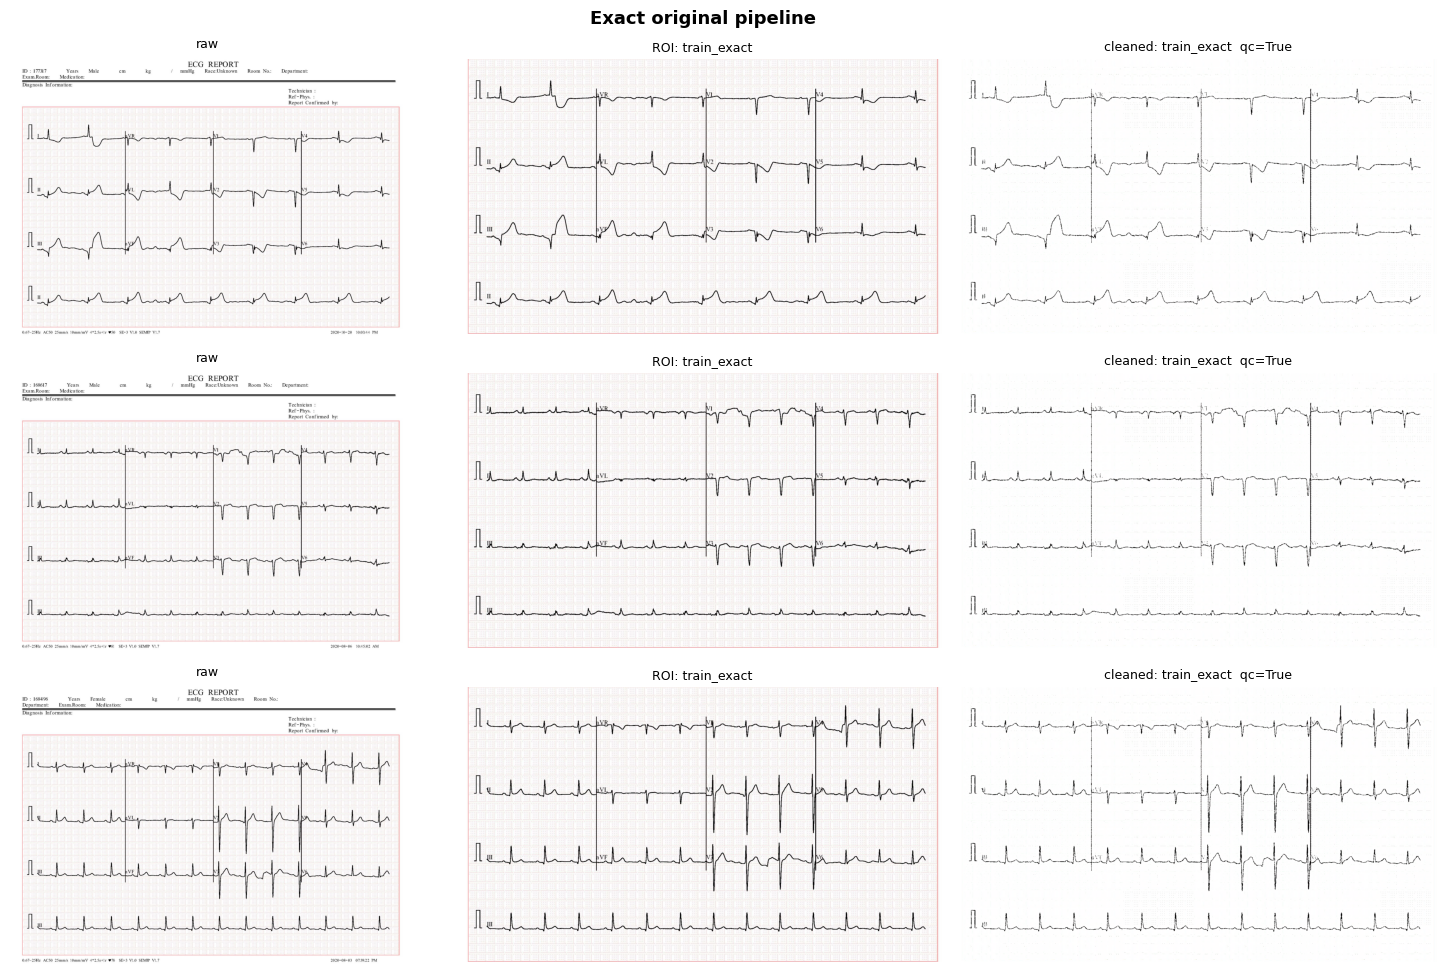

928 images used the exact original pipeline, 0 needed a fallback.


In [ ]:
# quick visual check: raw -> ROI crop -> cleaned (exact training pipeline vs. fallback strategies)
def show_stages(rows, title):
    if len(rows) == 0:
        return
    fig, ax = plt.subplots(len(rows), 3, figsize=(15, 3.3 * len(rows)))
    ax = np.atleast_2d(ax)
    for r_, (_, row) in enumerate(rows.iterrows()):
        rgb, info = preprocess_image(row["raw_path"], return_stages=True)
        for c_, (im, t) in enumerate([(info["_raw"], "raw"), (info["_roi"], f"ROI: {info['roi_method']}"),
                                      (rgb, f"cleaned: {info['clean_method']}  qc={info['qc_pass']}")]):
            ax[r_, c_].imshow(im); ax[r_, c_].axis("off"); ax[r_, c_].set_title(t, fontsize=9)
    plt.suptitle(title, fontsize=13, fontweight="bold"); plt.tight_layout(); plt.show()

ok = man[man["clean_path"].notna()]
primary = (ok["roi_method"] == "train_exact") & (ok["clean_method"] == "train_exact") & ok["qc_pass"]
show_stages(ok[primary].sample(min(3, int(primary.sum())), random_state=1), "Exact original pipeline")
show_stages(ok[~primary].sample(min(4, int((~primary).sum())), random_state=1), "Needed a fallback strategy - check these look sensible")
print(f"{int(primary.sum())} images used the exact original pipeline, {int((~primary).sum())} needed a fallback.")

## 7. Patient-level train / validation / test split
Whole patients are assigned to a split (separately for every class and source). The assertion at the end proves that no patient appears in two splits.

In [ ]:
data = man[man["clean_path"].notna()].copy().reset_index(drop=True)
data["label"] = data["class"].map({c: i for i, c in enumerate(class_names)})

rng = np.random.RandomState(SEED)
data["split"] = "train"
for (src, cls), d in data.groupby(["source", "class"]):
    gids = np.array(sorted(d["gid"].unique()))
    rng.shuffle(gids)
    G = len(gids)
    n_test = max(1, int(round(TEST_FRAC * G))) if G >= 3 else 0
    n_val  = max(1, int(round(VAL_FRAC * G)))  if G >= 3 else 0
    data.loc[data["gid"].isin(set(gids[:n_test])), "split"] = "test"
    data.loc[data["gid"].isin(set(gids[n_test:n_test + n_val])), "split"] = "val"

# ---- proof that there is no leakage ----
leak = data.groupby("gid")["split"].nunique()
assert (leak == 1).all(), f"{int((leak > 1).sum())} patients appear in more than one split!"
print("OK: no patient appears in more than one split.\n")

tab = (data.groupby(["split", "source", "class"]).agg(images=("gid", "size"), patients=("gid", "nunique")).reset_index())
display(tab.pivot_table(index=["source", "class"], columns="split", values=["images", "patients"], fill_value=0))

train_df = data[data["split"] == "train"].reset_index(drop=True)
val_df   = data[data["split"] == "val"].reset_index(drop=True)
test_df  = data[data["split"] == "test"].reset_index(drop=True)
print(f"\nTrain: {len(train_df)} | Val: {len(val_df)} | Test: {len(test_df)} images")
assert len(train_df) and len(val_df) and len(test_df), "A split is empty - the dataset is too small for the chosen fractions."

# ---- save the held-out TEST images (cleaned, full resolution) for the test notebook, plus the split manifest ----
if os.path.exists(HELDOUT_DIR):
    shutil.rmtree(HELDOUT_DIR)
for _, r in tqdm(test_df.iterrows(), total=len(test_df), desc="Saving held-out test images"):
    dst = os.path.join(HELDOUT_DIR, r["class"]); os.makedirs(dst, exist_ok=True)
    shutil.copy2(r["clean_path"], os.path.join(dst, r["name"]))
data[["source", "class", "split", "gid", "raw_path", "name", "roi_method", "clean_method", "qc_pass"]].to_csv(SPLIT_CSV, index=False)

# ---- class weights from the training split ----
counts = np.bincount(train_df["label"], minlength=NUM_CLASSES).astype(np.float64)
cw = counts.sum() / (NUM_CLASSES * np.maximum(counts, 1))
cw = cw / cw.mean()
class_weights = torch.tensor(cw, dtype=torch.float32) if USE_CLASS_WEIGHTS else None
print("Train class counts :", counts.astype(int).tolist())
print("Class weights      :", np.round(cw, 3).tolist() if USE_CLASS_WEIGHTS else "off")

# ---- config for the test notebook (written now so an interrupted run is still usable; completed at the end) ----
config = {
    "model_name": "convnext_atto + CBAM (v2)",
    "class_names": class_names, "num_classes": NUM_CLASSES,
    "img_size": max(IMG_H, IMG_W), "img_h": IMG_H, "img_w": IMG_W,
    "resize_mode": RESIZE_MODE, "rotation_fill": ROT_FILL, "tta_hflip": TTA_HFLIP,
    "imagenet_mean": IMAGENET_MEAN, "imagenet_std": IMAGENET_STD,
    "seed": SEED, "val_fraction": VAL_FRAC, "test_fraction": TEST_FRAC,
    "num_train": len(train_df), "num_val": len(val_df), "num_test": len(test_df),
    "qc": {k: float(v) for k, v in QC.items()},
    "grouping": GROUPING_DESCRIPTION, "extra_dataset_used": bool(EXTRA_DATA_SOURCE),
    "best_epoch": None, "best_val_macro_f1": None, "test_tta_acc": None,
}
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)
print("\nSaved config   :", CONFIG_PATH)
print("Saved test set :", HELDOUT_DIR)
print("Saved manifest :", SPLIT_CSV)

OK: no patient appears in more than one split.



images               \
split                                                       test  train   val   
source class                                                                    
main   ECG Images of Myocardial Infarction Patients (2...   36.0  167.0  36.0   
       ECG Images of Patient that have History of MI (...   26.0  120.0  26.0   
       ECG Images of Patient that have abnormal heartb...   35.0  163.0  35.0   
       Normal Person ECG Images (284x12=3408)               43.0  198.0  43.0   

                                                          patients         \
split                                                         test  train   
source class                                                                
main   ECG Images of Myocardial Infarction Patients (2...     36.0  167.0   
       ECG Images of Patient that have History of MI (...     26.0  120.0   
       ECG Images of Patient that have abnormal heartb...     35.0  163.0   
       Normal Person ECG Images (284x12=3408)                 43.0  198.0   

                                                                 
split                                                       val  
source class                                                     
main   ECG Images of Myocardial Infarction Patients (2...  36.0  
       ECG Images of Patient that have History of MI (...  26.0  
       ECG Images of Patient that have abnormal heartb...  35.0  
       Normal Person ECG Images (284x12=3408)              43.0


Train: 648 | Val: 140 | Test: 140 images


Saving held-out test images: 100%|██████████| 140/140 [00:01<00:00, 97.78it/s]

Train class counts : [167, 120, 163, 198]
Class weights      : [0.939, 1.307, 0.962, 0.792]

Saved config   : /content/drive/MyDrive/ECG_ConvNeXt_Atto_CBAM_v2/config.json
Saved test set : /content/drive/MyDrive/ECG_ConvNeXt_Atto_CBAM_v2/heldout_test_images
Saved manifest : /content/drive/MyDrive/ECG_ConvNeXt_Atto_CBAM_v2/split_manifest.csv


## 8. Datasets and augmentation

Train batches/epoch: 41 | Val batches: 9


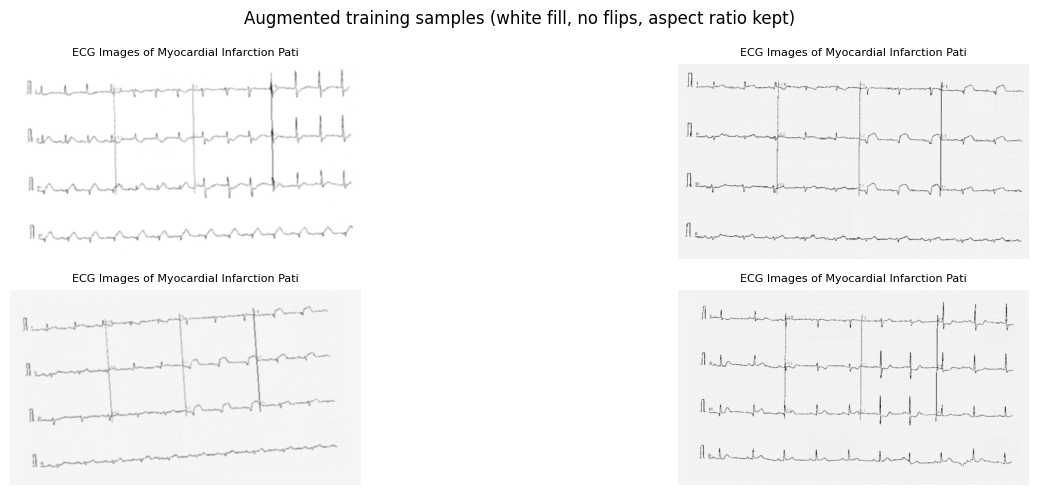

In [ ]:
class RandomDownUp:
    """Simulate a lower-resolution scan: shrink to 40-80 % and back up."""
    def __call__(self, img):
        s = random.uniform(0.4, 0.8)
        w, h = img.size
        small = img.resize((max(8, int(w * s)), max(8, int(h * s))), Image.BILINEAR)
        return small.resize((w, h), Image.BILINEAR)


train_transforms = transforms.Compose([
    base_resize(),
    transforms.RandomAffine(degrees=5, translate=(0.02, 0.03), scale=(0.93, 1.07), fill=255),   # white fill, no flips
    transforms.RandomApply([RandomDownUp()], p=0.3),
    transforms.RandomApply([transforms.GaussianBlur(3, sigma=(0.1, 1.0))], p=0.2),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
])


class CanvasDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = list(paths), list(labels), transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])


def make_loader(df, transform, shuffle):
    return DataLoader(CanvasDataset(df["canvas_path"], df["label"], transform), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"),
                      persistent_workers=(NUM_WORKERS > 0))

train_loader = make_loader(train_df, train_transforms, True)
val_loader   = make_loader(val_df, eval_transforms, False)
print(f"Train batches/epoch: {len(train_loader)} | Val batches: {len(val_loader)}")

# preview of augmented training samples
xb, yb = next(iter(DataLoader(CanvasDataset(train_df["canvas_path"][:8], train_df["label"][:8], train_transforms), batch_size=8)))
mean_t = torch.tensor(IMAGENET_MEAN).view(1, 3, 1, 1); std_t = torch.tensor(IMAGENET_STD).view(1, 3, 1, 1)
vis = (xb * std_t + mean_t).clamp(0, 1)
plt.figure(figsize=(16, 5))
for k in range(min(4, len(vis))):
    plt.subplot(2, 2, k + 1); plt.imshow(vis[k].permute(1, 2, 0).numpy()); plt.axis("off")
    plt.title(class_names[int(yb[k])][:40], fontsize=8)
plt.suptitle("Augmented training samples (white fill, no flips, aspect ratio kept)"); plt.tight_layout(); plt.show()

## 9. Model, loss, optimiser, schedule

In [ ]:
class CBAM(nn.Module):
    def __init__(self, planes, ratio=16):
        super().__init__()
        self.ca = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Conv2d(planes, planes // ratio, 1, bias=False),
            nn.ReLU(),
            nn.Conv2d(planes // ratio, planes, 1, bias=False),
            nn.Sigmoid(),
        )
        self.sa = nn.Sequential(
            nn.Conv2d(2, 1, 7, padding=3, bias=False),
            nn.Sigmoid(),
        )

    def forward(self, x):
        x = x * self.ca(x)
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        sa_out = self.sa(torch.cat([avg_out, max_out], dim=1))
        return x * sa_out


class ConvNeXtAttoCBAM(nn.Module):
    def __init__(self, num_classes=NUM_CLASSES, pretrained=True):
        super().__init__()
        self.backbone = timm.create_model('convnext_atto', pretrained=pretrained, features_only=True)
        in_features = self.backbone.feature_info[-1]['num_chs']   # 320 channels
        self.cbam = CBAM(planes=in_features)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Flatten(1),
            nn.LayerNorm(in_features, eps=1e-6),
            nn.Linear(in_features, 256),
            nn.GELU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        feats = self.backbone(x)[-1]
        x = self.cbam(feats)
        x = self.pool(x)
        return self.classifier(x)

In [ ]:
class FocalLossWithSmoothing(nn.Module):
    def __init__(self, gamma=2.0, smoothing=0.03, class_weights=None):
        super().__init__()
        self.gamma, self.smoothing = gamma, smoothing
        self.register_buffer("w", class_weights if class_weights is not None else torch.ones(NUM_CLASSES))

    def forward(self, inputs, targets):
        log_probs = F.log_softmax(inputs.float(), dim=-1)
        with torch.no_grad():
            true_dist = torch.full_like(log_probs, self.smoothing / (NUM_CLASSES - 1))
            true_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.smoothing)
        ce_loss = -(true_dist * log_probs).sum(dim=1)
        pt = torch.exp(-ce_loss)
        loss = ((1 - pt) ** self.gamma) * ce_loss * self.w[targets]
        return loss.mean()


model = ConvNeXtAttoCBAM(num_classes=NUM_CLASSES, pretrained=PRETRAINED).to(device)
criterion = FocalLossWithSmoothing(FOCAL_GAMMA, LABEL_SMOOTHING, class_weights).to(device)

backbone_params = [p for n, p in model.named_parameters() if "classifier" not in n and "cbam" not in n]
head_params     = [p for n, p in model.named_parameters() if "classifier" in n or "cbam" in n]
optimizer = torch.optim.AdamW([
    {"params": backbone_params, "lr": LR_BACKBONE},
    {"params": head_params,     "lr": LR_HEAD},
], weight_decay=WEIGHT_DECAY)

steps_per_epoch = len(train_loader)
total_steps, warm_steps = NUM_EPOCHS * steps_per_epoch, max(1, WARMUP_EPOCHS * steps_per_epoch)
def lr_lambda(step):
    if step < warm_steps:
        return (step + 1) / warm_steps
    prog = (step - warm_steps) / max(1, total_steps - warm_steps)
    return max(0.01, 0.5 * (1 + math.cos(math.pi * prog)))
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

params = sum(p.numel() for p in model.parameters())
print(f"Model ready! Total Parameters: {params:,} (~{params/1e6:.2f}M) | pretrained={PRETRAINED}")

## 10. Training
Per epoch: train loss / accuracy, validation loss / accuracy / macro-F1. The checkpoint with the best **validation** macro-F1 is saved to Drive;
training stops early after `PATIENCE` epochs without improvement. **The test set is not touched here.**

In [ ]:
scaler = amp.GradScaler("cuda", enabled=use_amp)

def evaluate(model, loader):
    model.eval()
    loss_sum, preds, targs = 0.0, [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
            with amp.autocast(device_type=device.type, enabled=use_amp):
                out = model(x)
            loss_sum += F.cross_entropy(out.float(), y, reduction="sum").item()
            preds.append(out.argmax(1).cpu().numpy()); targs.append(y.cpu().numpy())
    preds, targs = np.concatenate(preds), np.concatenate(targs)
    return (loss_sum / len(targs), float((preds == targs).mean()),
            float(f1_score(targs, preds, average="macro", zero_division=0)))

history, best_f1, best_vloss, best_epoch, bad_epochs = [], -1.0, float("inf"), 0, 0
print(f"Training up to {NUM_EPOCHS} epochs (early stopping patience {PATIENCE}) ...")
t0 = time.time()
for epoch in range(1, NUM_EPOCHS + 1):
    model.train()
    run_loss, run_correct, run_n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(device, non_blocking=True), y.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with amp.autocast(device_type=device.type, enabled=use_amp):
            out = model(x)
            loss = criterion(out, y)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
        scaler.step(optimizer); scaler.update(); scheduler.step()
        run_loss += loss.item() * len(y); run_correct += (out.argmax(1) == y).sum().item(); run_n += len(y)

    v_loss, v_acc, v_f1 = evaluate(model, val_loader)
    rec = {"epoch": epoch, "train_loss": run_loss / run_n, "train_acc": run_correct / run_n,
           "val_loss": v_loss, "val_acc": v_acc, "val_macro_f1": v_f1,
           "lr_backbone": optimizer.param_groups[0]["lr"], "seconds": round(time.time() - t0, 1)}
    history.append(rec)
    improved = (v_f1 > best_f1 + 1e-4) or (abs(v_f1 - best_f1) <= 1e-4 and v_loss < best_vloss)
    if improved:
        best_f1, best_vloss, best_epoch, bad_epochs = v_f1, v_loss, epoch, 0
        torch.save(model.state_dict(), CKPT_PATH)                      # straight to Drive
    else:
        bad_epochs += 1
    with open(HISTORY_PATH, "w") as f:
        json.dump(history, f, indent=2)
    print(f"Epoch [{epoch:>2}/{NUM_EPOCHS}] train loss {rec['train_loss']:.4f} acc {rec['train_acc']*100:5.2f}% | "
          f"val loss {v_loss:.4f} acc {v_acc*100:5.2f}% macroF1 {v_f1:.4f} | best F1 {best_f1:.4f} @ {best_epoch}"
          f"{'  *saved*' if improved else ''}")
    if bad_epochs >= PATIENCE:
        print(f"Early stopping: no validation improvement for {PATIENCE} epochs.")
        break
print(f"\nTraining finished in {time.time() - t0:.1f}s. Best epoch: {best_epoch} (val macro-F1 {best_f1:.4f})")

In [ ]:
h = pd.DataFrame(history)
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].plot(h["epoch"], h["train_loss"], label="train"); ax[0].plot(h["epoch"], h["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(h["epoch"], h["train_acc"], label="train"); ax[1].plot(h["epoch"], h["val_acc"], label="val"); ax[1].set_title("Accuracy"); ax[1].legend()
ax[2].plot(h["epoch"], h["val_macro_f1"], color="green"); ax[2].axvline(best_epoch, ls="--", color="grey"); ax[2].set_title("Validation macro-F1")
for a in ax:
    a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(os.path.join(SAVE_DIR, "training_curves.png"), dpi=120); plt.show()
gap = h["train_acc"].iloc[-1] - h["val_acc"].iloc[-1]
print(f"Final train acc {h['train_acc'].iloc[-1]*100:.1f}% vs val acc {h['val_acc'].iloc[-1]*100:.1f}% (gap {gap*100:.1f} points).")
print("Large gap = overfitting (add augmentation / data); both low = underfitting (train longer / higher LR).")

## 11. Final evaluation — the test set is used exactly once, with the checkpoint chosen on validation

In [ ]:
class TTAPathDataset(Dataset):
    """Opens each image ONCE and returns all TTA views stacked: [V, 3, H, W]."""
    def __init__(self, paths, views):
        self.paths, self.views = paths, views

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return torch.stack([v(img) for v in self.views])


def predict_tta_paths(model, paths, views=None, batch_size=4, num_workers=2):
    """Average softmax probabilities over all views in tta_transform_pool."""
    views = views or tta_transform_pool
    model.eval()
    if len(paths) == 0:
        return np.zeros((0, NUM_CLASSES))
    loader = DataLoader(TTAPathDataset(paths, views), batch_size=batch_size,
                        shuffle=False, num_workers=num_workers)
    out = []
    with torch.no_grad():
        for stack in tqdm(loader, desc="Predicting", total=len(loader)):
            B, V = stack.shape[:2]
            x = stack.reshape(B * V, *stack.shape[2:]).to(device)
            with amp.autocast(device_type=device.type, enabled=use_amp):
                logits = model(x)
            p = F.softmax(logits.float(), dim=1).reshape(B, V, -1).mean(dim=1)
            out.append(p.cpu().numpy())
    return np.concatenate(out, axis=0)


def report_metrics(y_true, y_pred, title):
    """Accuracy, per-class table (4 decimals), sklearn report and confusion matrix."""
    y_true = np.asarray(y_true); y_pred = np.asarray(y_pred)
    labels = list(range(NUM_CLASSES))
    acc = (y_true == y_pred).mean()
    print("=" * 56)
    print(f"   {title}: {acc * 100:.2f}%   (n = {len(y_true)})")
    print("=" * 56 + "\n")

    prec, rec, f1, sup = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    name_w = max(len(n) for n in class_names) + 2
    print(f"{'Class':<{name_w}}{'Precision':>11}{'Recall':>11}{'F1-score':>11}{'Support':>9}")
    print("-" * (name_w + 42))
    for i, name in enumerate(class_names):
        print(f"{name:<{name_w}}{prec[i]:>11.4f}{rec[i]:>11.4f}{f1[i]:>11.4f}{sup[i]:>9d}")
    print("-" * (name_w + 42))
    mp, mr, mf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="macro", zero_division=0)
    wp, wr, wf, _ = precision_recall_fscore_support(y_true, y_pred, labels=labels, average="weighted", zero_division=0)
    print(f"{'Macro avg':<{name_w}}{mp:>11.4f}{mr:>11.4f}{mf:>11.4f}{int(sup.sum()):>9d}")
    print(f"{'Weighted avg':<{name_w}}{wp:>11.4f}{wr:>11.4f}{wf:>11.4f}{int(sup.sum()):>9d}")
    print(f"\nAccuracy           : {acc:.4f}")
    print(f"Macro F1-score     : {mf:.4f}")
    print(f"Weighted F1-score  : {wf:.4f}")

    print("\nClassification report:\n")
    print(classification_report(y_true, y_pred, labels=labels, target_names=class_names, digits=4, zero_division=0))

    cm = confusion_matrix(y_true, y_pred, labels=labels)
    wrapped = [textwrap.fill(n, 28) for n in class_names]
    plt.figure(figsize=(11, 8))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=wrapped, yticklabels=wrapped)
    plt.title(f"Confusion Matrix - {title}", fontsize=13, fontweight="bold")
    plt.xlabel("Predicted Label"); plt.ylabel("True Label")
    plt.xticks(rotation=30, ha="right", fontsize=8); plt.yticks(rotation=0, fontsize=8)
    plt.tight_layout(); plt.show()
    return acc

In [ ]:
model.load_state_dict(torch.load(CKPT_PATH, map_location=device))
model.eval()
print(f"Loaded best checkpoint (epoch {best_epoch}).")

# the images are loaded from the cleaned full-resolution files and letterboxed on the fly - exactly what the test notebook does
val_probs  = predict_tta_paths(model, val_df["clean_path"].tolist(),  num_workers=NUM_WORKERS)
test_probs = predict_tta_paths(model, test_df["clean_path"].tolist(), num_workers=NUM_WORKERS)
test_single = predict_tta_paths(model, test_df["clean_path"].tolist(), views=[eval_transforms], num_workers=NUM_WORKERS)

val_acc_tta  = float((val_probs.argmax(1) == val_df["label"].values).mean())
test_pred    = test_probs.argmax(1)
test_acc_tta = float((test_pred == test_df["label"].values).mean())
test_acc_one = float((test_single.argmax(1) == test_df["label"].values).mean())
print(f"\nValidation accuracy (TTA): {val_acc_tta*100:.2f}%")
print(f"Test accuracy, single view: {test_acc_one*100:.2f}%")
print(f"Test accuracy, {len(tta_transform_pool)}-view TTA: {test_acc_tta*100:.2f}%\n")

report_metrics(test_df["label"].values, test_pred, f"TEST ACCURACY ({len(tta_transform_pool)}-VIEW TTA, patient-level split)")

test_df["pred"] = test_pred
test_df["correct"] = (test_pred == test_df["label"].values)
if test_df["source"].nunique() > 1:
    print("\nTest accuracy by data source (the 'extra' rows are your external dataset, held-out patients/images only):")
    display(test_df.groupby("source")["correct"].agg(n="size", accuracy="mean").round(4))
print("\nTest accuracy by preprocessing path:")
display(test_df.groupby(["roi_method", "clean_method"])["correct"].agg(n="size", accuracy="mean").round(4).reset_index())

## 12. Finalise: write the results into config.json

In [ ]:
config.update({"best_epoch": int(best_epoch), "best_val_macro_f1": float(best_f1),
               "val_tta_acc": val_acc_tta, "test_tta_acc": test_acc_tta, "test_single_view_acc": test_acc_one,
               "epochs_run": len(history)})
with open(CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=2)

print("=" * 56)
print("ALL ARTIFACTS SAVED IN:", SAVE_DIR)
print("=" * 56)
for name in sorted(os.listdir(SAVE_DIR)):
    print(" -", name)
print(f"\nValidation (TTA): {val_acc_tta*100:.2f}%   |   TEST (TTA, evaluated once): {test_acc_tta*100:.2f}%")
print("\nNext: open the TEST v2 notebook and set SAVE_DIR to this folder.")